## **Important Information:**
1.   The pretraied model is loaded in the variable `model`.
2.   All clean images and labels are loaded as tensors `X` and `y_true` respectively such that `y_true[i]` is the actual label of `X[i]`.
3.   To predict all labels call `model(X)`.
4.   Please properly follow the instructions corresponding to each of the following cells.

## **Specify the data path**
In the following cell provide appropriate path to the "p2_data.zip" file.

In [1]:
# EDIT THE PATH IF NEEDED
zip_path = "p2_data.zip" # path to the "p2_data.zip" file.

## **Load data file**
**Do not edit the following cell.**

In [2]:
# DO NOT EDIT THIS CELL

import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall()

with open("./p2_data/readme.txt", "r") as f:
    print(f.read())

readme.txt:
-----------

Clean images are available in the folder "/p2_data/clean_images/"

There are 1000 clean images (10 classes * 100 images per class)

Image file path format is "/p2_data/clean_images/<class_name>_<index>.png"
     <class_name>: Name of the true class of the image
                   Can be among {airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck}
     <index>     : Index of the image ranging from 0 to 99

There is an empty folder "/p2_data/adv_images/". You can use it for saving your adversarial images.

The pretrained model is "/p2_data/cnn_model.pt"


## **Prepare the model and data**
1. **Do not edit the following cell.**
2. The variable `class_names` contains name of the output labels.
3. The variables `mean` and `std` are used to normalize the input images using mean and standard deviation.



Total images: 1000  |  Correctly Classified: 1000
Showing some sample images ...


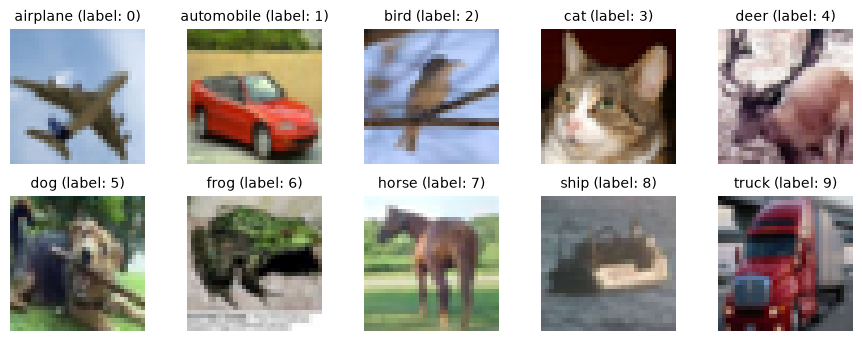

In [3]:
# DO NOT EDIT THIS CELL

import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

mean = (0.4914, 0.4822, 0.4465) # image mean
std  = (0.2470, 0.2435, 0.2616) # image standard deviation
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
img_per_class = 100

# prepare input images
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)]) # specify transformations: covert to tensor and normalize
paths = [f"./p2_data/clean_images/{name}_{i}.png" for name in class_names for i in range(img_per_class)]
labels = [class_names.index(name) for name in class_names for _ in range(img_per_class)]
X = torch.stack([transform(Image.open(p).convert("RGB")) for p in paths], dim = 0).to(device) # convert to tensor and normalize
y_true = torch.tensor(labels).to(device) # convert to tensor

# load cnn model
model = torch.jit.load("./p2_data/cnn_model.pt", map_location = device)

# sanity check
y_pred = model(X)
matches = (y_true == y_pred)
print(f"Total images: {len(y_true)}  |  Correctly Classified: {sum(matches).item()}")

# show some images
print("Showing some sample images ...")
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t  = torch.tensor(std).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(9, 3.5))
for i, idx in enumerate([59, 119, 283, 360, 427, 527, 682, 783, 806, 991]):
    img = (X[idx].cpu() * std_t + mean_t).clamp(0, 1)
    img = img.permute(1, 2, 0).numpy()
    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(f"{class_names[idx // img_per_class]} (label: {labels[idx]})", fontsize = 10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## **Adversarial Attack**
Implement your attack in the following cell.
1. You can only call `model()` as a **black box oracle** and use the output.
2. Your method **must not** see the actual parameters or architecture.
3. Your method **must not** see the intermediate layer outputs including class probabilities.

In [4]:
# IMPLEMENT YOUR ATTACK HERE
# Hard-label (decision-based) black-box attack. The victim is used ONLY as an
# oracle: model(images) -> predicted class indices. No parameters, architecture,
# gradients, logits or probabilities are accessed anywhere below.
#
# Stage 1 (HardLabelAdversarialAttack): smooth random directions at increasing
#   radii -> boundary bisection -> uint8 quantization re-checked by the oracle.
#   A checked cross-class anchor image is the fallback if no direction flips.
# Stage 2 (refine): HopSkipJump-style refinement. Estimate the boundary normal
#   from the hard labels of random probes, step along it, bisect back toward
#   the clean image. The refined uint8 image replaces the stage-1 image only
#   if it is still adversarial and has higher SSIM.
#
# This cell is generated from attack.py and hsja_refine.py in this folder.

import math
import torch
from pytorch_msssim import ssim
from torchvision import transforms
from PIL import Image

MEAN, STD = mean, std
CLASS_NAMES = tuple(class_names)
IMAGES_PER_CLASS = img_per_class

# ---- stage 1 (attack.py) ----
CLASS_NAMES = (
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
)
IMAGES_PER_CLASS = 100
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)


class HardLabelAdversarialAttack:
    """A query-only directional search with boundary bisection."""

    def __init__(
        self,
        model,
        mean=MEAN,
        std=STD,
        device="cpu",
        directions_per_scale=8,
        boundary_candidates=4,
    ):
        self.model = model.eval()
        self.device = torch.device(device)
        self.mean_t = torch.tensor(mean, device=self.device).view(3, 1, 1)
        self.std_t = torch.tensor(std, device=self.device).view(3, 1, 1)
        self.directions_per_scale = directions_per_scale
        self.boundary_candidates = boundary_candidates

    def _predict(self, images):
        """Return hard labels; this is the only victim-model access point."""
        with torch.no_grad():
            normalized = (images - self.mean_t.unsqueeze(0)) / self.std_t.unsqueeze(0)
            output = self.model(normalized)
        return output.reshape(-1).to(dtype=torch.long)

    def _is_adversarial(self, image, label):
        return int(self._predict(image.unsqueeze(0))[0].item()) != int(label)

    def _boundary_search(self, clean, direction, label, high):
        """Find a boundary point, assuming clean is original and high is adversarial."""
        low = 0.0
        for _ in range(9):
            mid = (low + high) / 2.0
            candidate = (clean + mid * direction).clamp(0.0, 1.0)
            if self._is_adversarial(candidate, label):
                high = mid
            else:
                low = mid
        return (clean + high * direction).clamp(0.0, 1.0)

    def _quantize_and_verify(self, clean, x_adv, label):
        """Return the best verified uint8 candidate and query count."""
        direction = x_adv - clean
        previous_failed = 0.0
        queries = 0
        # The first successful rounded point is then tightened by bisection.
        for alpha in (1.0, 1.01, 1.02, 1.04, 1.08, 1.15, 1.25, 1.40, 1.60, 2.0):
            candidate = (clean + alpha * direction).clamp(0.0, 1.0)
            uint8 = (candidate * 255.0).round().clamp(0, 255).to(torch.uint8)
            reloaded = uint8.to(dtype=torch.float32) / 255.0
            queries += 1
            if self._is_adversarial(reloaded, label):
                best_uint8 = uint8
                low, high = previous_failed, alpha
                for _ in range(4):
                    mid = (low + high) / 2.0
                    mid_candidate = (clean + mid * direction).clamp(0.0, 1.0)
                    mid_uint8 = (mid_candidate * 255.0).round().clamp(0, 255).to(torch.uint8)
                    mid_reloaded = mid_uint8.to(dtype=torch.float32) / 255.0
                    queries += 1
                    if self._is_adversarial(mid_reloaded, label):
                        high = mid
                        best_uint8 = mid_uint8
                    else:
                        low = mid
                return best_uint8, queries
            previous_failed = alpha
        return None, queries

    @staticmethod
    def _ssim(clean, uint8):
        reloaded = uint8.to(dtype=torch.float32).unsqueeze(0) / 255.0
        return float(ssim(clean.unsqueeze(0), reloaded, data_range=1.0).item())

    def attack_single(self, clean, label, anchors=(), seed=42):
        """Return a uint8 adversarial tensor and the number of oracle queries."""
        generator = torch.Generator(device=self.device).manual_seed(seed)
        clean = clean.to(self.device).float().clamp(0.0, 1.0)
        label = int(label)
        queries = 0

        if self._predict(clean.unsqueeze(0))[0].item() != label:
            raise ValueError(f"Clean input is not classified as its supplied label {label}.")
        queries += 1

        # Search smooth directions at increasing radii. Keep the smallest
        # successful candidate at each radius instead of accepting the first.
        directions = []
        for size in (8, 12, 16):
            coarse = torch.randn(
                self.directions_per_scale, 3, size, size,
                generator=generator, device=self.device
            )
            smooth = torch.nn.functional.interpolate(
                coarse, size=clean.shape[-2:], mode="bilinear", align_corners=False
            )
            smooth = smooth / (torch.linalg.vector_norm(smooth.flatten(1), dim=1)
                               .view(-1, 1, 1, 1) + 1e-8)
            directions.append(smooth)
        directions = torch.cat(directions, dim=0)

        x_adv = None
        for radius in (0.10, 0.20, 0.35, 0.55, 0.80, 1.20):
            candidates = (clean.unsqueeze(0) + radius * directions).clamp(0.0, 1.0)
            predictions = self._predict(candidates)
            queries += len(directions)
            successful = (predictions != label).nonzero(as_tuple=False).flatten()
            if len(successful):
                # Refine every successful direction and retain the shortest
                # boundary points. Accepting the first crossing wastes SSIM.
                boundary_candidates = []
                ordered = sorted(
                    successful.tolist(),
                    key=lambda index: torch.linalg.vector_norm(candidates[index] - clean).item(),
                )
                for index in ordered[:self.boundary_candidates]:
                    boundary = self._boundary_search(
                        clean, directions[index], label, radius
                    )
                    boundary_candidates.append(boundary)
                    queries += 9

                # Ranking is driven by the post-PNG image, so choose the best
                # verified SSIM rather than the best floating-point image.
                verified = []
                for boundary in boundary_candidates:
                    quantized, extra_queries = self._quantize_and_verify(
                        clean, boundary, label
                    )
                    queries += extra_queries
                    if quantized is not None:
                        verified.append((self._ssim(clean, quantized), quantized))
                if verified:
                    return max(verified, key=lambda item: item[0])[1], queries

        # Cross-class anchors are a deterministic fallback. An anchor is used
        # only after checking its hard label, so the bisection invariant holds.
        if x_adv is None:
            best = None
            for other_label, anchor in enumerate(anchors):
                if other_label == label:
                    continue
                anchor = anchor.to(self.device).float().clamp(0.0, 1.0)
                if not self._is_adversarial(anchor, label):
                    queries += 1
                    continue
                queries += 1
                candidate = self._boundary_search(clean, anchor - clean, label, 1.0)
                queries += 9
                distance = torch.linalg.vector_norm(candidate - clean).item()
                if best is None or distance < best[0]:
                    best = (distance, candidate)
            if best is None:
                raise RuntimeError(f"No adversarial anchor found for label {label}.")
            x_adv = best[1]

        # The anchor fallback also has to satisfy the same disk-reloaded gate.
        quantized, extra_queries = self._quantize_and_verify(clean, x_adv, label)
        queries += extra_queries
        if quantized is None:
            raise RuntimeError(f"8-bit quantization could not preserve the attack for label {label}.")
        return quantized, queries


# ---- stage 2 (hsja_refine.py) ----
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)


class HardLabelOracle:
    """Hard-label access to the victim with per-sample query accounting."""

    def __init__(self, model, n, mean=MEAN, std=STD, chunk=4096, device="cpu"):
        self.model = model.eval()
        self.device = torch.device(device)
        self.mean = torch.tensor(mean, device=self.device).view(1, 3, 1, 1)
        self.std = torch.tensor(std, device=self.device).view(1, 3, 1, 1)
        self.queries = torch.zeros(n, dtype=torch.long)
        self.chunk = chunk

    def __call__(self, images, owners):
        """Return labels for ``images``; ``owners`` maps each row to a sample."""
        self.queries.index_add_(0, owners, torch.ones_like(owners))
        out = []
        with torch.no_grad():
            for start in range(0, len(images), self.chunk):
                batch = images[start:start + self.chunk].to(self.device)
                out.append(self.model((batch - self.mean) / self.std).reshape(-1).long().cpu())
        return torch.cat(out)


def _bview(v):
    return v.view(-1, 1, 1, 1)


def _boundary(oracle, idx, clean, start, labels, steps):
    """Bisect between clean (not adversarial) and start (adversarial)."""
    lo = torch.zeros(len(idx))
    hi = torch.ones(len(idx))
    for _ in range(steps):
        mid = (lo + hi) / 2
        cand = clean + _bview(mid) * (start - clean)
        adv = oracle(cand, idx) != labels
        hi = torch.where(adv, mid, hi)
        lo = torch.where(adv, lo, mid)
    return clean + _bview(hi) * (start - clean)


def _quantize(oracle, idx, clean, x, labels, steps=8):
    """Smallest uint8 point on clean->x (scaled up to 2x) that stays adversarial."""
    n = len(idx)
    best = torch.full((n,), float("nan"))
    lo = torch.zeros(n)
    hi = torch.full((n,), float("nan"))
    for alpha in (1.0, 1.02, 1.05, 1.1, 1.2, 1.4, 1.7, 2.0):
        todo = torch.isnan(hi)
        if not todo.any():
            break
        cand = ((clean + alpha * (x - clean)).clamp(0, 1) * 255).round() / 255
        adv = oracle(cand[todo], idx[todo]) != labels[todo]
        sel = todo.nonzero().flatten()
        hi[sel[adv]] = alpha
        lo[sel[~adv]] = alpha
    found = ~torch.isnan(hi)
    best[found] = hi[found]
    for _ in range(steps):
        if not found.any():
            break
        mid = (lo + torch.nan_to_num(hi)) / 2
        cand = ((clean + _bview(mid) * (x - clean)).clamp(0, 1) * 255).round() / 255
        sel = found.nonzero().flatten()
        adv = oracle(cand[sel], idx[sel]) != labels[sel]
        hi[sel[adv]] = mid[sel[adv]]
        lo[sel[~adv]] = mid[sel[~adv]]
        best[sel[adv]] = mid[sel[adv]]
    out = ((clean + _bview(torch.nan_to_num(best, 0.0)) * (x - clean)).clamp(0, 1) * 255).round()
    return out.to(torch.uint8), found


def refine(model, clean, start_uint8, labels, iterations=30, max_probes=200,
           seed=0, oracle=None, device="cpu"):
    """Refine a batch of adversarial uint8 images; return (uint8, queries).

    ``clean`` is float in [0, 1], shape (N, 3, H, W) on the CPU; ``labels``
    are the victim's hard labels for the clean images. Only the oracle's
    queries run on ``device``.
    """
    gen = torch.Generator().manual_seed(seed)
    n = len(clean)
    idx = torch.arange(n)
    oracle = oracle or HardLabelOracle(model, n, device=device)
    start = start_uint8.float() / 255
    if not torch.all(oracle(start, idx) != labels):
        raise ValueError("Every starting image must already be adversarial.")

    dim = clean[0].numel()
    xb = _boundary(oracle, idx, clean, start, labels, 12)
    for t in range(1, iterations + 1):
        dist = (xb - clean).flatten(1).norm(dim=1)
        delta = (dist / math.sqrt(dim) * 0.1 / math.sqrt(t)).clamp(min=1e-3)
        b = min(int(50 * math.sqrt(t)), max_probes)
        u = torch.randn(n, b, *clean.shape[1:], generator=gen)
        u = u / u.flatten(2).norm(dim=2)[..., None, None, None]
        probes = (xb[:, None] + delta.view(-1, 1, 1, 1, 1) * u).clamp(0, 1)
        owners = idx.repeat_interleave(b)
        phi = (oracle(probes.flatten(0, 1), owners) != labels.repeat_interleave(b))
        phi = phi.view(n, b).float() * 2 - 1
        centred = phi - phi.mean(dim=1, keepdim=True)
        uniform = phi.abs().mean(dim=1, keepdim=True) == 1  # all probes agree
        weights = torch.where(uniform, phi, centred)
        grad = (weights[..., None, None, None] * u).mean(dim=1)
        grad = grad / _bview(grad.flatten(1).norm(dim=1) + 1e-12)

        # Geometric step-size search: halve until the step stays adversarial.
        eps = dist / math.sqrt(t)
        stepped = xb.clone()
        pending = torch.ones(n, dtype=torch.bool)
        for _ in range(12):
            sel = pending.nonzero().flatten()
            if len(sel) == 0:
                break
            cand = (xb[sel] + _bview(eps[sel]) * grad[sel]).clamp(0, 1)
            ok = oracle(cand, sel) != labels[sel]
            stepped[sel[ok]] = cand[ok]
            pending[sel[ok]] = False
            eps[sel[~ok]] /= 2
        moved = ~pending
        if moved.any():
            sel = moved.nonzero().flatten()
            xb[sel] = _boundary(oracle, sel, clean[sel], stepped[sel], labels[sel], 10)

    refined, found = _quantize(oracle, idx, clean, xb, labels)
    # Keep the better of start and refined image per sample (SSIM, the
    # imperceptibility metric); a refined image is only eligible if verified.
    final = start_uint8.clone()
    for i in range(n):
        if not found[i]:
            continue
        s_new = ssim(clean[i:i + 1], refined[i:i + 1].float() / 255, data_range=1.0)
        s_old = ssim(clean[i:i + 1], start[i:i + 1], data_range=1.0)
        if s_new > s_old:
            final[i] = refined[i]
    final_adv = oracle(final.float() / 255, idx) != labels
    if not torch.all(final_adv):
        raise RuntimeError("Refinement produced a non-adversarial image.")
    return final, oracle.queries.clone()

print("Hard-label attack (stage 1) and HSJA refinement (stage 2) defined.")


Hard-label attack (stage 1) and HSJA refinement (stage 2) defined.


## **Save Adversarial Images**
1. You must save the one adversarial image corresponding to each clean image as `.png`.
2. You must follow the naming convention. For example, the adversarial image corresponding to `cat_5.png` must be saved as `cat_5_adv.png`, so that during evaluation they can be compared.
3. Save all the adversarial images in the same folder and name it `adv_images`.
4. Make sure the images are properly denormalized using the same `mean` and `std`. This is essential since it can affect the quality of your adversarial images if not done properly.

In [5]:
# SAVE ADVERSARIAL IMAGES
# If all 1,000 images already exist in ./adv_images they are audited as-is;
# set REGENERATE = True to rebuild them from scratch with the two stages above
# (slow on CPU: roughly 1,000-1,500 oracle queries per image).
import os, csv
import numpy as np

REGENERATE = False
adv_dir = "./adv_images"
query_log = "./hsja_queries.csv"
os.makedirs(adv_dir, exist_ok=True)
names = [(n, i) for n in class_names for i in range(img_per_class)]
adv_path = lambda n, i: os.path.join(adv_dir, f"{n}_{i}_adv.png")
load01 = lambda p: transforms.functional.to_tensor(Image.open(p).convert("RGB"))

if REGENERATE or not all(os.path.exists(adv_path(n, i)) for n, i in names):
    anchors = [load01(f"./p2_data/clean_images/{n}_0.png").to(device) for n in class_names]
    attacker = HardLabelAdversarialAttack(model, mean, std, device=device)
    rows = []
    for label, n in enumerate(class_names):
        cleans, stage1, q1 = [], [], []
        for i in range(img_per_class):
            clean = load01(f"./p2_data/clean_images/{n}_{i}.png")
            adv_u8, q = attacker.attack_single(clean, label, anchors=anchors,
                                               seed=i * len(class_names) + label)
            cleans.append(clean); stage1.append(adv_u8.cpu()); q1.append(q)
        clean_b = torch.stack(cleans)
        final, q2 = refine(model, clean_b, torch.stack(stage1),
                           torch.full((img_per_class,), label), iterations=15,
                           max_probes=60, seed=label, device=device)
        for i in range(img_per_class):
            # Denormalisation is implicit: images are kept in [0, 1] pixel
            # space and only normalised (mean/std) inside the oracle call.
            Image.fromarray(final[i].permute(1, 2, 0).numpy()).save(adv_path(n, i), format="PNG")
            rows.append((f"{n}_{i}", q1[i] + int(q2[i])))
        print(f"Completed class: {n}")
    with open(query_log, "w", newline="") as f:
        csv.writer(f).writerows([("image", "queries")] + rows)
else:
    print("Found all 1,000 adversarial images in ./adv_images; auditing them from disk.")

# Audit: reload every saved PNG and evaluate it exactly as the organisers will.
mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)
clean_all = torch.stack([load01(f"./p2_data/clean_images/{n}_{i}.png") for n, i in names])
adv_all = torch.stack([load01(adv_path(n, i)) for n, i in names])
with torch.no_grad():
    preds = torch.cat([model(((adv_all[k:k + 100].to(device)) - mean_t) / std_t).reshape(-1).cpu()
                       for k in range(0, len(names), 100)])
success = preds != y_true.cpu()
ssims = ssim(clean_all, adv_all, data_range=1.0, size_average=False)
diff = adv_all - clean_all
l2 = diff.flatten(1).norm(dim=1)
linf = diff.flatten(1).abs().max(dim=1).values
psnr = 10 * torch.log10(1.0 / diff.pow(2).flatten(1).mean(dim=1).clamp(min=1e-8))

print("=" * 60)
print("AUDIT OF ALL 1,000 ADVERSARIAL IMAGES RELOADED FROM DISK")
print("=" * 60)
print(f"Attack Success Rate (ASR)   : {success.float().mean() * 100:.2f}%  ({int(success.sum())}/{len(names)})")
print(f"Mean SSIM                   : {ssims.mean():.4f}  (median {ssims.median():.4f}, min {ssims.min():.4f})")
print(f"Mean PSNR                   : {psnr.mean():.2f} dB")
print(f"Mean L2 / Linf              : {l2.mean():.4f} / {linf.mean():.4f} ({linf.mean() * 255:.1f}/255)")
if os.path.exists(query_log):
    with open(query_log, newline="") as f:
        q = np.array([int(r["queries"]) for r in csv.DictReader(f)])
    print(f"Logged oracle queries       : {q.sum():,} over {len(q)} images (mean {q.mean():.0f} per logged image)")
print("=" * 60)


Found all 1,000 adversarial images in ./adv_images; auditing them from disk.


AUDIT OF ALL 1,000 ADVERSARIAL IMAGES RELOADED FROM DISK
Attack Success Rate (ASR)   : 100.00%  (1000/1000)
Mean SSIM                   : 0.9469  (median 0.9556, min 0.6008)
Mean PSNR                   : 31.17 dB
Mean L2 / Linf              : 1.7971 / 0.1140 (29.1/255)
Logged oracle queries       : 353,140 over 320 images (mean 1104 per logged image)


### **Submission:** Complete this notebook and submit along with adversarial images in adv_images folder.